# TP3: Initialization and Regularization

**How this notebook works**
1. **Follow along (Parts 0–2).** We go through the notebook together.
2. **Assignment (at the end).** On your own: 8 exercises, to be submitted.

| Part | Topic | Lecture 3 slides |
|---|---|---|
| 0 | Setup and helper functions | |
| 1 | Initialization: zeros, large random, He; then `nn.init` | Initialization of Parameters · Vanishing and exploding gradients · Weight initialization for deep networks |
| 2 | Regularization: L2 and dropout; then `weight_decay` and `nn.Dropout` | L2 regularization: neural network · Dropout regularization · Why does dropout work? |
| ★ | Assignment: moons, Tanh, spirals, regularization | |

**Notation:** $\mathbf{X}$ has shape $(m, n^{[0]})$, $\mathbf{W}^{[l]}$ has shape $(n^{[l-1]}, n^{[l]})$, $\mathbf{b}^{[l]}$ has shape $(1, n^{[l]})$, and $\mathbf{Z}^{[l]} = \mathbf{A}^{[l-1]}\mathbf{W}^{[l]} + \mathbf{b}^{[l]}$. Labels $\mathbf{Y}$ have shape $(m, 1)$.

## 0 · Setup and helper functions

In [1]:
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles, make_moons
from sklearn.model_selection import train_test_split

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_printoptions(precision=4, sci_mode=False)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.14.1+cu130 | device: cuda


Three helpers used everywhere:
- `accuracy_fn(y_true, y_pred)`: the percentage of correct predictions.
- `accuracy(model, X, y)`: runs a model that outputs **logits** in evaluation mode and returns its accuracy. A "model" can be an `nn.Module` or any function, such as our hand-written network.
- `plot_decision_boundary(model, X, y)`: colors the plane by the predicted class. It works for binary models (one logit) and multi-class models (one logit per class), like the helper of Bourke's notebook.

In [2]:
def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    return correct / len(y_pred) * 100

def predict_labels(logits):
    # binary: one logit -> sigmoid -> round; multi-class: argmax over the classes
    if logits.shape[1] == 1:
        return torch.round(torch.sigmoid(logits))
    return logits.argmax(dim=1)

def accuracy(model, X, y):
    if isinstance(model, nn.Module):
        model.eval()
        X, y = X.to(device), y.to(device)
    with torch.inference_mode():
        return accuracy_fn(y, predict_labels(model(X)))

def plot_decision_boundary(model, X, y, lim=None):
    X, y = X.cpu(), y.cpu()
    lo, hi = (X.min() - 0.2, X.max() + 0.2) if lim is None else (-lim, lim)
    xx, yy = torch.meshgrid(torch.linspace(lo, hi, 300), torch.linspace(lo, hi, 300), indexing="xy")
    grid = torch.stack([xx.flatten(), yy.flatten()], dim=1)
    if isinstance(model, nn.Module):
        model.eval(); grid = grid.to(device)
    with torch.inference_mode():
        Z = predict_labels(model(grid)).reshape(300, 300).cpu()
    plt.contourf(xx, yy, Z, alpha=0.6, cmap=plt.cm.RdYlBu)
    plt.scatter(X[:, 0], X[:, 1], c=y.flatten(), s=14, cmap=plt.cm.RdYlBu, edgecolors="k", linewidths=0.3)
    plt.xlim(lo, hi); plt.ylim(lo, hi)

**The 3-layer network, by hand.** LINEAR → ReLU → LINEAR → ReLU → LINEAR → sigmoid. You know every line from Lecture 2 and the follow-along; here it is written out for exactly three layers, so that we can modify it in Part 2.

In [3]:
def compute_cost(A3, Y, eps=1e-7):
    # Binary cross-entropy, averaged over the m examples.
    A3 = A3.clamp(eps, 1 - eps)
    return -(Y * torch.log(A3) + (1 - Y) * torch.log(1 - A3)).mean()

def forward_propagation(X, params):
    Z1 = X @ params["W1"] + params["b1"]
    A1 = torch.relu(Z1)
    Z2 = A1 @ params["W2"] + params["b2"]
    A2 = torch.relu(Z2)
    Z3 = A2 @ params["W3"] + params["b3"]
    A3 = torch.sigmoid(Z3)
    cache = (Z1, A1, Z2, A2, Z3, A3)
    return A3, cache

def backward_propagation(X, Y, params, cache):
    m = X.shape[0]
    Z1, A1, Z2, A2, Z3, A3 = cache
    dZ3 = A3 - Y
    dW3 = A2.T @ dZ3 / m
    db3 = dZ3.sum(dim=0, keepdim=True) / m
    dA2 = dZ3 @ params["W3"].T
    dZ2 = dA2 * (Z2 > 0).float()
    dW2 = A1.T @ dZ2 / m
    db2 = dZ2.sum(dim=0, keepdim=True) / m
    dA1 = dZ2 @ params["W2"].T
    dZ1 = dA1 * (Z1 > 0).float()
    dW1 = X.T @ dZ1 / m
    db1 = dZ1.sum(dim=0, keepdim=True) / m
    return {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2, "dW3": dW3, "db3": db3}

def update_parameters(params, grads, lr):
    return {k: params[k] - lr * grads["d" + k] for k in params}

def logits_by_hand(params):
    # turns a dictionary of parameters into a "model": X -> Z3 (logits)
    return lambda X: forward_propagation(X, params)[1][4]

def plot_costs(costs, title, every):
    plt.figure(figsize=(5, 3))
    plt.plot([every * i for i in range(len(costs))], costs)
    plt.xlabel("iteration"); plt.ylabel("cost"); plt.title(title); plt.grid(alpha=0.3); plt.show()

## 1 · Initialization

### 1.1 The data
Two circles, one inside the other: 300 training points and 100 test points with 2 features. No straight line separates them, so the network needs its hidden layers.

In [4]:
def load_circles():
    Xtr, ytr = make_circles(n_samples=300, noise=0.05, random_state=1)
    Xte, yte = make_circles(n_samples=100, noise=0.05, random_state=2)
    to_t = lambda a: torch.tensor(a, dtype=torch.float32)
    return to_t(Xtr), to_t(ytr).reshape(-1, 1), to_t(Xte), to_t(yte).reshape(-1, 1)

train_X (300, 2) | train_Y (300, 1) | test_X (100, 2)


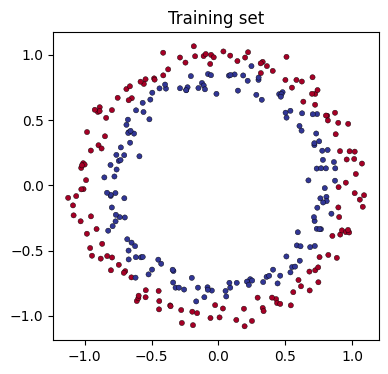

In [5]:
train_X, train_Y, test_X, test_Y = load_circles()
print("train_X", tuple(train_X.shape), "| train_Y", tuple(train_Y.shape), "| test_X", tuple(test_X.shape))
plt.figure(figsize=(4.2, 4))
plt.scatter(train_X[:, 0], train_X[:, 1], c=train_Y.flatten(), s=14, cmap=plt.cm.RdYlBu, edgecolors="k", linewidths=0.3)
plt.title("Training set"); plt.show()

### 1.2 The model, by hand
`model` trains the 3-layer network `[2, 10, 5, 1]` with batch gradient descent. The only thing that changes between experiments is the **initialization**: `"zeros"`, `"random"` or `"he"`. The three functions are defined just after.

In [6]:
def model(X, Y, initialization="he", lr=0.01, num_iters=15000, print_every=100):
    layer_dims = [X.shape[1], 10, 5, 1]
    if initialization == "zeros":
        params = initialize_parameters_zeros(layer_dims)
    elif initialization == "random":
        params = initialize_parameters_random(layer_dims)
    elif initialization == "he":
        params = initialize_parameters_he(layer_dims)
    costs = []
    for i in range(num_iters):
        A3, cache = forward_propagation(X, params)
        cost = compute_cost(A3, Y)
        grads = backward_propagation(X, Y, params, cache)
        params = update_parameters(params, grads, lr)
        if print_every and i % print_every == 0:
            costs.append(cost.item())
            if i % (5 * print_every) == 0:
                print(f"Cost after iteration {i}: {cost.item():.4f}")
    return params, costs

def show(params, costs, title):
    print(f"train accuracy {accuracy(logits_by_hand(params), train_X, train_Y):.1f}% | "
          f"test accuracy {accuracy(logits_by_hand(params), test_X, test_Y):.1f}%")
    plot_costs(costs, title, 1000)
    plt.figure(figsize=(4.2, 4)); plt.title(title)
    plot_decision_boundary(logits_by_hand(params), train_X, train_Y, lim=1.5); plt.show()

### 1.3 Zero initialization
All weights and biases start at 0. Shapes: $\mathbf{W}^{[l]}$ is $(n^{[l-1]}, n^{[l]})$ and $\mathbf{b}^{[l]}$ is $(1, n^{[l]})$.

In [7]:
def initialize_parameters_zeros(layer_dims):
    params = {}
    for l in range(1, len(layer_dims)):
        params[f"W{l}"] = torch.zeros(layer_dims[l - 1], layer_dims[l])
        params[f"b{l}"] = torch.zeros(1, layer_dims[l])
    return params

for k, v in initialize_parameters_zeros([3, 2, 1]).items():
    print(k, "=", v.tolist())

W1 = [[0.0, 0.0], [0.0, 0.0], [0.0, 0.0]]
b1 = [[0.0, 0.0]]
W2 = [[0.0], [0.0]]
b2 = [[0.0]]


In [8]:
params_zeros, costs_zeros = model(train_X, train_Y, initialization="zeros")

Cost after iteration 0: 0.6931
Cost after iteration 500: 0.6931
Cost after iteration 1000: 0.6931
Cost after iteration 1500: 0.6931
Cost after iteration 2000: 0.6931
Cost after iteration 2500: 0.6931
Cost after iteration 3000: 0.6931
Cost after iteration 3500: 0.6931
Cost after iteration 4000: 0.6931
Cost after iteration 4500: 0.6931
Cost after iteration 5000: 0.6931
Cost after iteration 5500: 0.6931
Cost after iteration 6000: 0.6931
Cost after iteration 6500: 0.6931
Cost after iteration 7000: 0.6931
Cost after iteration 7500: 0.6931
Cost after iteration 8000: 0.6931
Cost after iteration 8500: 0.6931
Cost after iteration 9000: 0.6931
Cost after iteration 9500: 0.6931
Cost after iteration 10000: 0.6931
Cost after iteration 10500: 0.6931
Cost after iteration 11000: 0.6931
Cost after iteration 11500: 0.6931
Cost after iteration 12000: 0.6931
Cost after iteration 12500: 0.6931
Cost after iteration 13000: 0.6931
Cost after iteration 13500: 0.6931
Cost after iteration 14000: 0.6931
Cost afte

train accuracy 50.0% | test accuracy 50.0%


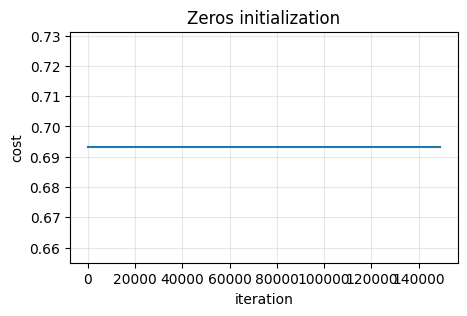

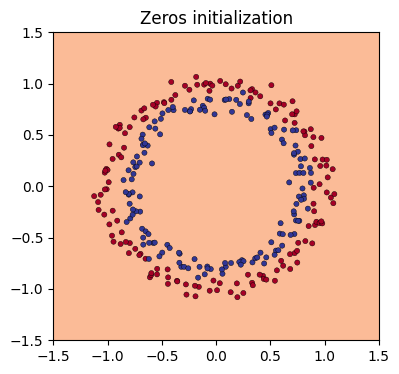

In [9]:
show(params_zeros, costs_zeros, "Zeros initialization")

The cost never moves from $\log 2 = 0.6931$, and the model predicts the same class for every point: 50% accuracy.

**Why?** With all weights 0, every $\mathbf{Z}^{[l]}$ is 0, every ReLU outputs 0, and the sigmoid outputs $\sigma(0) = 0.5$ for every example. The gradients of $\mathbf{W}^{[2]}$ and $\mathbf{W}^{[3]}$ are products with activations that are all 0, and the error sent back through $\mathbf{W}^{[3]} = \mathbf{0}$ is 0: only $b^{[3]}$ could move, and it stays at 0 because the two classes are balanced. More generally, units that start equal compute the same thing and get the same update forever: the network cannot **break the symmetry**.

**Remember:** initialize $\mathbf{W}^{[l]}$ randomly. The biases $\mathbf{b}^{[l]}$ can start at 0.

### 1.4 Large random initialization
Random weights break the symmetry. Here we try **large** ones: `torch.randn(...) * 10`.

In [10]:
def initialize_parameters_random(layer_dims, seed=3):
    torch.manual_seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        params[f"W{l}"] = torch.randn(layer_dims[l - 1], layer_dims[l]) * 100
        params[f"b{l}"] = torch.zeros(1, layer_dims[l])
    return params

In [11]:
params_random, costs_random = model(train_X, train_Y, initialization="random")

Cost after iteration 0: 7.3742
Cost after iteration 500: 1.8181
Cost after iteration 1000: 1.7327
Cost after iteration 1500: 1.2464
Cost after iteration 2000: 1.1651
Cost after iteration 2500: 1.0781
Cost after iteration 3000: 1.0705
Cost after iteration 3500: 1.3691
Cost after iteration 4000: 0.5498
Cost after iteration 4500: 1.2791
Cost after iteration 5000: 1.3066
Cost after iteration 5500: 1.0451
Cost after iteration 6000: 1.0127
Cost after iteration 6500: 0.6397
Cost after iteration 7000: 0.9313
Cost after iteration 7500: 0.9239
Cost after iteration 8000: 0.9287
Cost after iteration 8500: 1.1548
Cost after iteration 9000: 0.6871
Cost after iteration 9500: 0.9443
Cost after iteration 10000: 0.9592
Cost after iteration 10500: 0.9330
Cost after iteration 11000: 1.2031
Cost after iteration 11500: 0.6796
Cost after iteration 12000: 0.6169
Cost after iteration 12500: 0.9332
Cost after iteration 13000: 0.6135
Cost after iteration 13500: 0.9342
Cost after iteration 14000: 0.5570
Cost afte

train accuracy 68.3% | test accuracy 65.0%


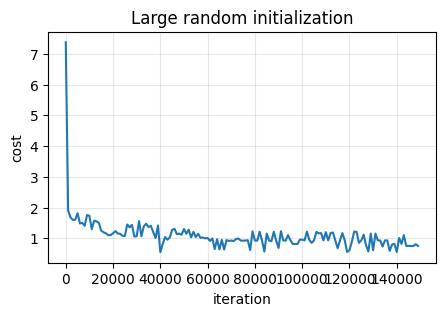

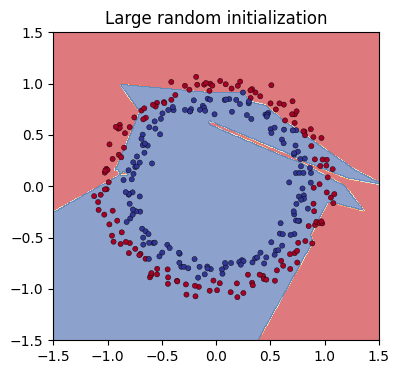

In [12]:
show(params_random, costs_random, "Large random initialization")

The symmetry is broken and the model learns something, but slowly:

- The **first cost is very large.** With weights of size 10, $\mathbf{Z}^{[3]}$ is huge, the sigmoid outputs almost exactly 0 or 1, and every wrong prediction costs $-\log(\text{almost } 0)$. (Without the `clamp` in `compute_cost`, the cost would be `inf`.)
- Saturated outputs and huge activations make the optimization slow and unstable: the activations are close to **exploding**.

### 1.5 He initialization
For ReLU layers, He et al. (2015) scale the random weights by $\sqrt{2 / n^{[l-1]}}$ (lecture: "Weight initialization for deep networks").

In [13]:
def initialize_parameters_he(layer_dims, seed=3):
    torch.manual_seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        params[f"W{l}"] = torch.randn(layer_dims[l - 1], layer_dims[l]) * (2 / layer_dims[l - 1]) ** 0.5
        params[f"b{l}"] = torch.zeros(1, layer_dims[l])
    return params

In [14]:
params_he, costs_he = model(train_X, train_Y, initialization="he")

Cost after iteration 0: 0.7258
Cost after iteration 500: 0.6867
Cost after iteration 1000: 0.6828
Cost after iteration 1500: 0.6795
Cost after iteration 2000: 0.6759
Cost after iteration 2500: 0.6707
Cost after iteration 3000: 0.6642
Cost after iteration 3500: 0.6563
Cost after iteration 4000: 0.6454
Cost after iteration 4500: 0.6322
Cost after iteration 5000: 0.6168
Cost after iteration 5500: 0.5978
Cost after iteration 6000: 0.5745
Cost after iteration 6500: 0.5488
Cost after iteration 7000: 0.5179
Cost after iteration 7500: 0.4846
Cost after iteration 8000: 0.4455
Cost after iteration 8500: 0.4060
Cost after iteration 9000: 0.3544
Cost after iteration 9500: 0.3080
Cost after iteration 10000: 0.2687
Cost after iteration 10500: 0.2371
Cost after iteration 11000: 0.2109
Cost after iteration 11500: 0.1892
Cost after iteration 12000: 0.1709
Cost after iteration 12500: 0.1558
Cost after iteration 13000: 0.1431
Cost after iteration 13500: 0.1327
Cost after iteration 14000: 0.1240
Cost afte

train accuracy 97.7% | test accuracy 94.0%


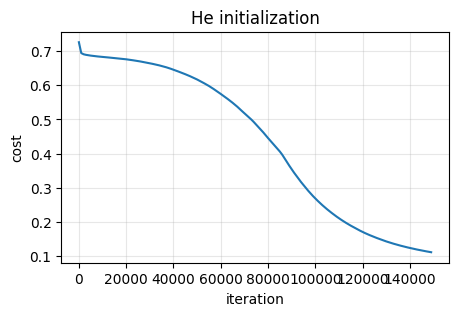

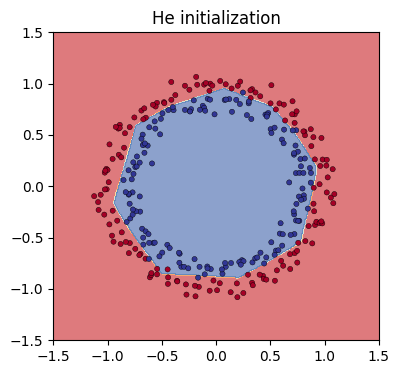

In [15]:
show(params_he, costs_he, "He initialization")

### 1.6 Using PyTorch

| By hand | `torch.nn` |
|---|---|
| `torch.zeros(n_prev, n_l)` | `nn.init.zeros_(layer.weight)` |
| `torch.randn(n_prev, n_l) * 10` | `nn.init.normal_(layer.weight, mean=0.0, std=10.0)` |
| `torch.randn(n_prev, n_l) * (2 / n_prev) ** 0.5` | `nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")` |
| `torch.zeros(1, n_l)` | `nn.init.zeros_(layer.bias)` |

**One difference to remember:** `nn.Linear` stores its weight as `(n_out, n_in)`, the transpose of our $\mathbf{W}^{[l]}$, and computes `X @ weight.T + bias`. "Kaiming" is He's first name; by default it uses `n_in` (the "fan-in"), as in the lecture.

In [16]:
class CircleModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=2, out_features=10)
        self.layer_2 = nn.Linear(in_features=10, out_features=5)
        self.layer_3 = nn.Linear(in_features=5, out_features=1)
        self.relu = nn.ReLU()

    def forward(self, x):
        # LINEAR -> RELU -> LINEAR -> RELU -> LINEAR (logits)
        return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))

def init_weights(model, method, seed=3):
    torch.manual_seed(seed)
    for layer in model.modules():
        if isinstance(layer, nn.Linear):
            if method == "zeros":
                nn.init.zeros_(layer.weight)
            elif method == "random":
                nn.init.normal_(layer.weight, mean=0.0, std=10.0)
            elif method == "he":
                nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
            nn.init.zeros_(layer.bias)
    return model

model_0 = init_weights(CircleModel(), "he").to(device)
print(model_0)
print("layer_1.weight:", tuple(model_0.layer_1.weight.shape), "= (n_out, n_in) | std",
      round(model_0.layer_1.weight.std().item(), 3), "| sqrt(2 / n_in) =", round((2 / 2) ** 0.5, 3))

CircleModel(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=5, bias=True)
  (layer_3): Linear(in_features=5, out_features=1, bias=True)
  (relu): ReLU()
)
layer_1.weight: (10, 2) = (n_out, n_in) | std 0.676 | sqrt(2 / n_in) = 1.0


In [17]:
check_model = CircleModel()
p = initialize_parameters_he([2, 10, 5, 1])
with torch.no_grad():
    for l, layer in zip([1, 2, 3], [check_model.layer_1, check_model.layer_2, check_model.layer_3]):
        layer.weight.copy_(p[f"W{l}"].T)          # (n_in, n_out) -> (n_out, n_in)
        layer.bias.copy_(p[f"b{l}"].flatten())

A3_hand, cache = forward_propagation(train_X, p)
grads = backward_propagation(train_X, train_Y, p, cache)
loss = nn.BCEWithLogitsLoss()(check_model(train_X), train_Y)
loss.backward()                                    # autograd

print(f"sigmoid(logits) vs A3: max difference {(torch.sigmoid(check_model(train_X)) - A3_hand).abs().max().item():.1e}")
for l, layer in zip([1, 2, 3], [check_model.layer_1, check_model.layer_2, check_model.layer_3]):
    print(f"dW{l}: max difference {(layer.weight.grad.T - grads[f'dW{l}']).abs().max().item():.1e} | "
          f"db{l}: max difference {(layer.bias.grad - grads[f'db{l}'].flatten()).abs().max().item():.1e}")

sigmoid(logits) vs A3: max difference 0.0e+00
dW1: max difference 7.5e-09 | db1: max difference 3.7e-09
dW2: max difference 3.0e-08 | db2: max difference 3.7e-09
dW3: max difference 1.9e-09 | db3: max difference 0.0e+00


In [18]:
def train_and_test(model, loss_fn, optimizer, X_train, y_train, X_test, y_test, epochs, print_every=None):
    X_train, y_train = X_train.to(device), y_train.to(device)
    X_test, y_test = X_test.to(device), y_test.to(device)
    for epoch in range(epochs):
        ### Training
        model.train()
        y_logits = model(X_train)                       # 1. forward pass (logits)
        y_pred = torch.round(torch.sigmoid(y_logits))   #    logits -> probabilities -> labels
        loss = loss_fn(y_logits, y_train)               # 2. loss
        acc = accuracy_fn(y_true=y_train, y_pred=y_pred)
        optimizer.zero_grad()                           # 3. zero the gradients
        loss.backward()                                 # 4. backpropagation
        optimizer.step()                                # 5. gradient descent step

        ### Testing
        model.eval()
        with torch.inference_mode():
            test_logits = model(X_test)
            test_pred = torch.round(torch.sigmoid(test_logits))
            test_loss = loss_fn(test_logits, y_test)
            test_acc = accuracy_fn(y_true=y_test, y_pred=test_pred)

        if print_every and epoch % print_every == 0:
            print(f"Epoch: {epoch:5d} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")
    return model

In [19]:
torch.manual_seed(42)
model_0 = init_weights(CircleModel(), "he").to(device)
loss_fn = nn.BCEWithLogitsLoss()                                 # sigmoid + binary cross-entropy
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.01)
model_0 = train_and_test(model_0, loss_fn, optimizer, train_X, train_Y, test_X, test_Y, epochs=15000, print_every=100)

Epoch:     0 | Loss: 0.69057, Accuracy: 50.00% | Test loss: 0.69148, Test acc: 50.00%
Epoch:   100 | Loss: 0.68471, Accuracy: 51.67% | Test loss: 0.68563, Test acc: 50.00%
Epoch:   200 | Loss: 0.68217, Accuracy: 51.67% | Test loss: 0.68317, Test acc: 50.00%
Epoch:   300 | Loss: 0.68055, Accuracy: 52.33% | Test loss: 0.68171, Test acc: 52.00%
Epoch:   400 | Loss: 0.67924, Accuracy: 55.33% | Test loss: 0.68061, Test acc: 54.00%
Epoch:   500 | Loss: 0.67802, Accuracy: 55.33% | Test loss: 0.67959, Test acc: 54.00%
Epoch:   600 | Loss: 0.67683, Accuracy: 56.67% | Test loss: 0.67859, Test acc: 57.00%
Epoch:   700 | Loss: 0.67562, Accuracy: 57.33% | Test loss: 0.67753, Test acc: 58.00%
Epoch:   800 | Loss: 0.67436, Accuracy: 57.33% | Test loss: 0.67642, Test acc: 61.00%
Epoch:   900 | Loss: 0.67305, Accuracy: 58.00% | Test loss: 0.67530, Test acc: 60.00%
Epoch:  1000 | Loss: 0.67164, Accuracy: 58.67% | Test loss: 0.67409, Test acc: 60.00%
Epoch:  1100 | Loss: 0.67021, Accuracy: 59.00% | Test 

initialization      train     test
zeros               50.0%    50.0%
random              79.0%    76.0%
he                  98.7%    93.0%
default             97.3%    92.0%


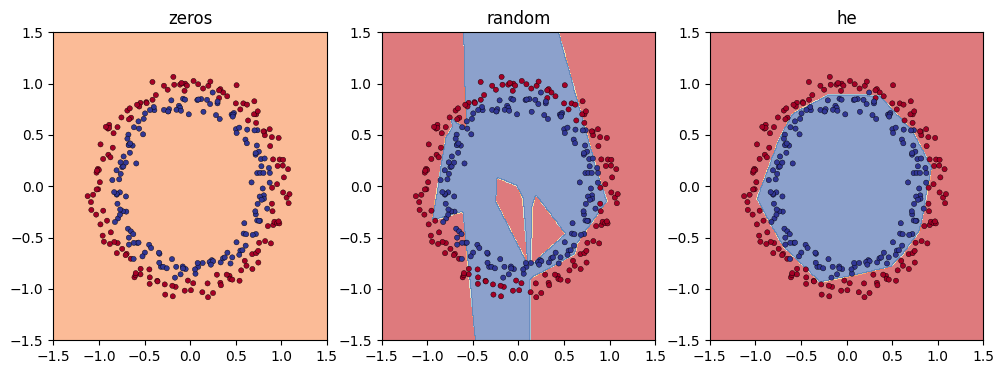

In [20]:
results_init = {}
for method in ["zeros", "random", "he", "default"]:
    torch.manual_seed(3)
    m = CircleModel()                          # PyTorch's default initialization
    if method != "default":
        init_weights(m, method)
    m = m.to(device)
    opt = torch.optim.SGD(m.parameters(), lr=0.01)
    train_and_test(m, nn.BCEWithLogitsLoss(), opt, train_X, train_Y, test_X, test_Y, epochs=15000)
    results_init[method] = (accuracy(m, train_X, train_Y), accuracy(m, test_X, test_Y))

print(f"{'initialization':16s} {'train':>8s} {'test':>8s}")
for method, (tr, te) in results_init.items():
    print(f"{method:16s} {tr:7.1f}% {te:7.1f}%")

plt.figure(figsize=(12, 4))
for k, method in enumerate(["zeros", "random", "he"]):
    torch.manual_seed(3)
    m = init_weights(CircleModel(), method).to(device)
    train_and_test(m, nn.BCEWithLogitsLoss(), torch.optim.SGD(m.parameters(), lr=0.01), train_X, train_Y, test_X, test_Y, epochs=15000)
    plt.subplot(1, 3, k + 1); plt.title(method); plot_decision_boundary(m, train_X, train_Y, lim=1.5)
plt.show()

**What to remember from Part 1**
- Different initializations give very different results with the same network and the same training.
- Random weights break the symmetry; weights that are too large saturate the output and slow down learning.
- For ReLU networks, use He initialization: `nn.init.kaiming_normal_(w, nonlinearity="relu")`.

---
## 2 · Regularization

### 2.1 The data
A noisy 2-D dataset: 211 training points and 200 test points. The true boundary is a gentle curve, but the training labels contain mistakes: about 6% random errors, plus a few small **pockets** of wrong labels (for example, a region labeled by a careless annotator). The test labels contain only the random errors. A network that fits the pockets will generalize badly.

In [21]:
def make_noisy_2d(m, seed, pockets=()):
    rng = np.random.default_rng(seed)
    X = rng.uniform(-1, 1, (m, 2))                                  # uniform in [-1, 1]^2
    Y = (X[:, 1] > 0.35 * np.sin(2.2 * X[:, 0]) - 0.1 * X[:, 0]).astype(float)
    flip = rng.random(m) < 0.06                                     # random label errors
    for cx, cy, r in pockets:                                       # pockets of wrong labels
        inside = (X[:, 0] - cx) ** 2 + (X[:, 1] - cy) ** 2 < r ** 2
        flip |= inside & (rng.random(m) < 0.7)
    Y[flip] = 1 - Y[flip]
    return torch.tensor(X, dtype=torch.float32), torch.tensor(Y, dtype=torch.float32).reshape(-1, 1)

train (211, 2) | test (200, 2) | fraction of class 1: 0.5


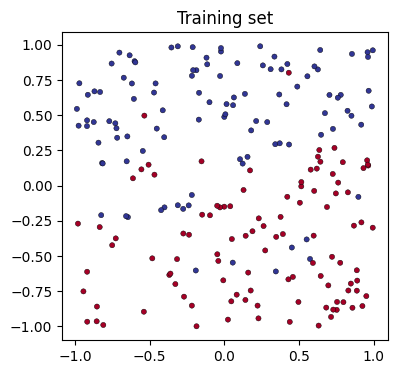

In [22]:
POCKETS = [(-0.55, 0.05, 0.12), (0.1, 0.45, 0.10), (0.5, -0.45, 0.12), (-0.2, -0.55, 0.10)]
reg_train_X, reg_train_Y = make_noisy_2d(211, seed=0, pockets=POCKETS)
reg_test_X, reg_test_Y = make_noisy_2d(200, seed=1)
print("train", tuple(reg_train_X.shape), "| test", tuple(reg_test_X.shape), "| fraction of class 1:", round(reg_train_Y.mean().item(), 2))
plt.figure(figsize=(4.2, 4))
plt.scatter(reg_train_X[:, 0], reg_train_X[:, 1], c=reg_train_Y.flatten(), s=14, cmap=plt.cm.RdYlBu, edgecolors="k", linewidths=0.3)
plt.title("Training set"); plt.show()

### 2.2 The baseline model, by hand
The network is `[2, 20, 3, 1]`, initialized with $\sqrt{1/n^{[l-1]}}$ and trained for 30,000 iterations with $\alpha = 0.3$. `model_reg` can run in three modes:
- no regularization: `lambd = 0`, `keep_prob = 1`;
- **L2 regularization**: `lambd > 0` (we write `lambd` because `lambda` is a Python keyword);
- **dropout**: `keep_prob < 1`.

The L2 and dropout functions it calls are written in 2.3 and 2.4.

Cost after iteration 0: 0.7019
Cost after iteration 1000: 0.2248
Cost after iteration 2000: 0.2015
Cost after iteration 3000: 0.1924
Cost after iteration 4000: 0.1659
Cost after iteration 5000: 0.1523
Cost after iteration 6000: 0.1447
Cost after iteration 7000: 0.1435
Cost after iteration 8000: 0.1337
Cost after iteration 9000: 0.1310
Cost after iteration 10000: 0.1380
Cost after iteration 11000: 0.1298
Cost after iteration 12000: 0.1247
Cost after iteration 13000: 0.1217
Cost after iteration 14000: 0.1181
Cost after iteration 15000: 0.1123
Cost after iteration 16000: 0.1021
Cost after iteration 17000: 0.1512
Cost after iteration 18000: 0.0802
Cost after iteration 19000: 0.1786
Cost after iteration 20000: 0.0629
Cost after iteration 21000: 0.0906
Cost after iteration 22000: 0.0693
Cost after iteration 23000: 0.0529
Cost after iteration 24000: 0.0493
Cost after iteration 25000: 0.0583
Cost after iteration 26000: 0.0691
Cost after iteration 27000: 0.1152
Cost after iteration 28000: 0.037

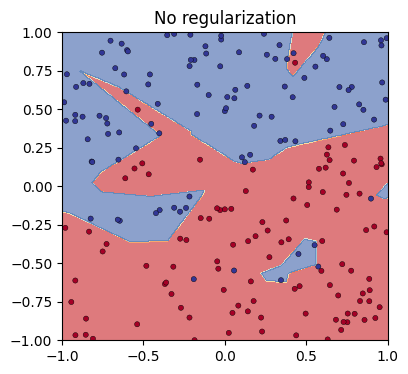

In [23]:
def initialize_parameters(layer_dims, seed=3):
    torch.manual_seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        params[f"W{l}"] = torch.randn(layer_dims[l - 1], layer_dims[l]) / layer_dims[l - 1] ** 0.5
        params[f"b{l}"] = torch.zeros(1, layer_dims[l])
    return params

def model_reg(X, Y, lr=0.3, num_iters=30000, lambd=0.0, keep_prob=1.0, print_every=1000, seed=1):
    params = initialize_parameters([X.shape[1], 20, 3, 1])
    gen = torch.Generator().manual_seed(seed)          # random masks for dropout
    for i in range(num_iters):
        if keep_prob == 1:
            A3, cache = forward_propagation(X, params)
        else:
            A3, cache = forward_propagation_with_dropout(X, params, keep_prob, gen)
        if lambd == 0:
            cost = compute_cost(A3, Y)
        else:
            cost = compute_cost_with_regularization(A3, Y, params, lambd)
        if lambd == 0 and keep_prob == 1:
            grads = backward_propagation(X, Y, params, cache)
        elif lambd != 0:
            grads = backward_propagation_with_regularization(X, Y, params, cache, lambd)
        else:
            grads = backward_propagation_with_dropout(X, Y, params, cache, keep_prob)
        params = update_parameters(params, grads, lr)
        if print_every and i % print_every == 0:
            print(f"Cost after iteration {i}: {cost.item():.4f}")
    return params

def report(name, model):
    tr = accuracy(model, reg_train_X, reg_train_Y)
    te = accuracy(model, reg_test_X, reg_test_Y)
    print(f"{name}: train accuracy {tr:.1f}% | test accuracy {te:.1f}%")
    return tr, te

def plot_reg(model, title):
    plt.figure(figsize=(4.2, 4)); plt.title(title)
    plot_decision_boundary(model, reg_train_X, reg_train_Y, lim=1.0); plt.show()

results_reg = {}
params_base = model_reg(reg_train_X, reg_train_Y)
results_reg["no regularization"] = report("no regularization", logits_by_hand(params_base))
plot_reg(logits_by_hand(params_base), "No regularization")

This is the **baseline**. Compare the training and the test accuracy, and look at the boundary: it bends around the pockets of wrong labels. The model is **overfitting** (high variance).

### 2.3 L2 regularization, by hand
The cost gets a penalty on the size of the weights (lecture: "L2 regularization: neural network"):
$$J_{\text{regularized}} = \underbrace{-\frac{1}{m}\sum_{i=1}^{m}\Big(y^{(i)}\log a^{[3](i)} + (1-y^{(i)})\log\big(1-a^{[3](i)}\big)\Big)}_{\text{cross-entropy cost}} + \underbrace{\frac{\lambda}{2m}\sum_{l=1}^{3}\lVert\mathbf{W}^{[l]}\rVert_F^2}_{\text{L2 cost}}$$
and, because the cost changed, every weight gradient gets an extra term: $d\mathbf{W}^{[l]} = (\text{from backprop}) + \frac{\lambda}{m}\mathbf{W}^{[l]}$. The biases are not regularized.

Cost after iteration 0: 0.7342
Cost after iteration 1000: 0.2991
Cost after iteration 2000: 0.2953
Cost after iteration 3000: 0.2931
Cost after iteration 4000: 0.2918
Cost after iteration 5000: 0.2906
Cost after iteration 6000: 0.2894
Cost after iteration 7000: 0.2889
Cost after iteration 8000: 0.2883
Cost after iteration 9000: 0.2881
Cost after iteration 10000: 0.2880
Cost after iteration 11000: 0.2879
Cost after iteration 12000: 0.2880
Cost after iteration 13000: 0.2879
Cost after iteration 14000: 0.2879
Cost after iteration 15000: 0.2879
Cost after iteration 16000: 0.2878
Cost after iteration 17000: 0.2878
Cost after iteration 18000: 0.2878
Cost after iteration 19000: 0.2879
Cost after iteration 20000: 0.2878
Cost after iteration 21000: 0.2878
Cost after iteration 22000: 0.2882
Cost after iteration 23000: 0.2878
Cost after iteration 24000: 0.2878
Cost after iteration 25000: 0.2877
Cost after iteration 26000: 0.2878
Cost after iteration 27000: 0.2877
Cost after iteration 28000: 0.288

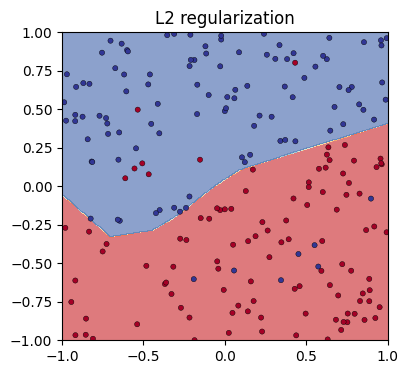

In [24]:
def compute_cost_with_regularization(A3, Y, params, lambd):
    m = Y.shape[0]
    cross_entropy_cost = compute_cost(A3, Y)
    L2_cost = lambd / (2 * m) * sum((params[f"W{l}"] ** 2).sum() for l in [1, 2, 3])
    return cross_entropy_cost + L2_cost

def backward_propagation_with_regularization(X, Y, params, cache, lambd):
    m = X.shape[0]
    grads = backward_propagation(X, Y, params, cache)     # the usual gradients
    for l in [1, 2, 3]:
        grads[f"dW{l}"] = grads[f"dW{l}"] + lambd / m * params[f"W{l}"]
    return grads

params_L2 = model_reg(reg_train_X, reg_train_Y, lambd=0.7)
results_reg["L2, lambda = 0.7"] = report("L2, lambda = 0.7", logits_by_hand(params_L2))
plot_reg(logits_by_hand(params_L2), "L2 regularization")

Compare with the baseline: the training accuracy should go **down** and the test accuracy **up**, and the boundary should no longer bend around the pockets. Smaller weights give a simpler, smoother function.

`backward_propagation_with_regularization` reuses `backward_propagation` and only adds $\frac{\lambda}{m}\mathbf{W}^{[l]}$: the regularization changes nothing else.

### 2.4 Dropout, by hand
Inverted dropout on the two hidden layers (lecture: "Dropout regularization"). For layer 1, at **every** iteration:
1. draw a mask `D1` of the same shape as `A1`, $(m, n^{[1]})$, with 1 with probability `keep_prob` and 0 otherwise;
2. `A1 = A1 * D1`: shut down the dropped units;
3. `A1 = A1 / keep_prob`: keep the expected value of `A1` unchanged.

In the backward pass, apply the **same** mask and the same scaling to `dA1`. Same for layer 2. No dropout on the input or the output layer.

Cost after iteration 0: 0.7146
Cost after iteration 1000: 0.3121
Cost after iteration 2000: 0.2387
Cost after iteration 3000: 0.2588
Cost after iteration 4000: 0.2644
Cost after iteration 5000: 0.2714
Cost after iteration 6000: 0.2174
Cost after iteration 7000: 0.2323
Cost after iteration 8000: 0.1942
Cost after iteration 9000: 0.2002
Cost after iteration 10000: 0.2032
Cost after iteration 11000: 0.2299
Cost after iteration 12000: 0.2047
Cost after iteration 13000: 0.2782
Cost after iteration 14000: 0.2127
Cost after iteration 15000: 0.1875
Cost after iteration 16000: 0.1976
Cost after iteration 17000: 0.2346
Cost after iteration 18000: 0.2299
Cost after iteration 19000: 0.1991
Cost after iteration 20000: 0.1904
Cost after iteration 21000: 0.1669
Cost after iteration 22000: 0.2021
Cost after iteration 23000: 0.1688
Cost after iteration 24000: 0.1826
Cost after iteration 25000: 0.2579
Cost after iteration 26000: 0.2124
Cost after iteration 27000: 0.2197
Cost after iteration 28000: 0.185

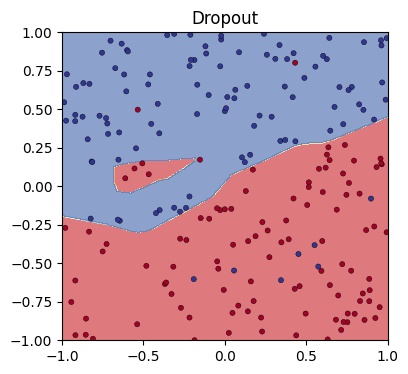

In [25]:
def forward_propagation_with_dropout(X, params, keep_prob, gen):
    Z1 = X @ params["W1"] + params["b1"]
    A1 = torch.relu(Z1)
    D1 = (torch.rand(A1.shape, generator=gen) < keep_prob).float()    # step 1
    A1 = A1 * D1                                                      # step 2
    A1 = A1 / keep_prob                                               # step 3
    Z2 = A1 @ params["W2"] + params["b2"]
    A2 = torch.relu(Z2)
    D2 = (torch.rand(A2.shape, generator=gen) < keep_prob).float()
    A2 = A2 * D2 / keep_prob
    Z3 = A2 @ params["W3"] + params["b3"]
    A3 = torch.sigmoid(Z3)
    cache = (Z1, D1, A1, Z2, D2, A2, Z3, A3)
    return A3, cache

def backward_propagation_with_dropout(X, Y, params, cache, keep_prob):
    m = X.shape[0]
    Z1, D1, A1, Z2, D2, A2, Z3, A3 = cache
    dZ3 = A3 - Y
    dW3 = A2.T @ dZ3 / m
    db3 = dZ3.sum(dim=0, keepdim=True) / m
    dA2 = dZ3 @ params["W3"].T
    dA2 = dA2 * D2 / keep_prob                 # same mask, same scaling
    dZ2 = dA2 * (Z2 > 0).float()
    dW2 = A1.T @ dZ2 / m
    db2 = dZ2.sum(dim=0, keepdim=True) / m
    dA1 = dZ2 @ params["W2"].T
    dA1 = dA1 * D1 / keep_prob
    dZ1 = dA1 * (Z1 > 0).float()
    dW1 = X.T @ dZ1 / m
    db1 = dZ1.sum(dim=0, keepdim=True) / m
    return {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2, "dW3": dW3, "db3": db3}

params_drop = model_reg(reg_train_X, reg_train_Y, keep_prob=0.86)
results_reg["dropout, keep_prob = 0.86"] = report("dropout, keep_prob = 0.86", logits_by_hand(params_drop))
plot_reg(logits_by_hand(params_drop), "Dropout")

### 2.5 Using PyTorch
| By hand | PyTorch |
|---|---|
| `compute_cost_with_regularization` and $+\frac{\lambda}{m}\mathbf{W}^{[l]}$ in backprop | `weight_decay=λ/m` in the optimizer |
| masks `D1`, `D2`, divide by `keep_prob` | `nn.Dropout(p=1 - keep_prob)` after each hidden ReLU |
| no dropout at test time | `model.eval()` (and `model.train()` to go back) |

Two details:
- **`p` in `nn.Dropout` is the probability of *dropping* a unit**, so `p = 1 - keep_prob`.
- `weight_decay` applies to every parameter it is given. To regularize only the weights, as in the lecture, give the optimizer two **parameter groups**.

In [26]:
class RegModel(nn.Module):
    def __init__(self, keep_prob=1.0):
        super().__init__()
        self.layer_1 = nn.Linear(2, 20)
        self.layer_2 = nn.Linear(20, 3)
        self.layer_3 = nn.Linear(3, 1)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=1 - keep_prob)      # p = probability of DROPPING a unit

    def forward(self, x):
        x = self.dropout(self.relu(self.layer_1(x)))
        x = self.dropout(self.relu(self.layer_2(x)))
        return self.layer_3(x)                          # logits

def make_optimizer(model, lr, lambd, m):
    weights = [p for name, p in model.named_parameters() if name.endswith("weight")]
    biases = [p for name, p in model.named_parameters() if name.endswith("bias")]
    return torch.optim.SGD([{"params": weights, "weight_decay": lambd / m},
                            {"params": biases, "weight_decay": 0.0}], lr=lr)

print(RegModel(keep_prob=0.86))

RegModel(
  (layer_1): Linear(in_features=2, out_features=20, bias=True)
  (layer_2): Linear(in_features=20, out_features=3, bias=True)
  (layer_3): Linear(in_features=3, out_features=1, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.14, inplace=False)
)


**Check 1: `weight_decay` does exactly what our L2 code does.** One step with `weight_decay=λ/m` versus one step with the penalty written in the cost:

In [27]:
lambd, m = 0.7, reg_train_X.shape[0]
torch.manual_seed(0); model_a = RegModel()
torch.manual_seed(0); model_b = RegModel()

# (a) weight_decay in the optimizer
opt_a = make_optimizer(model_a, lr=0.3, lambd=lambd, m=m)
loss_a = nn.BCEWithLogitsLoss()(model_a(reg_train_X), reg_train_Y)
opt_a.zero_grad(); loss_a.backward(); opt_a.step()

# (b) the L2 penalty written in the cost, plain SGD
opt_b = torch.optim.SGD(model_b.parameters(), lr=0.3)
penalty = lambd / (2 * m) * sum((layer.weight ** 2).sum() for layer in [model_b.layer_1, model_b.layer_2, model_b.layer_3])
loss_b = nn.BCEWithLogitsLoss()(model_b(reg_train_X), reg_train_Y) + penalty
opt_b.zero_grad(); loss_b.backward(); opt_b.step()

diff = max((pa - pb).abs().max().item() for pa, pb in zip(model_a.parameters(), model_b.parameters()))
print(f"max difference between the parameters after one step: {diff:.1e}")

max difference between the parameters after one step: 0.0e+00


Identical up to rounding. Note that `loss_a` does **not** contain the penalty: with `weight_decay`, the regularization lives in the update rule, not in the printed loss.

**Check 2: `nn.Dropout` is inverted dropout.** On a tensor of ones, in training mode and in evaluation mode:

In [28]:
torch.manual_seed(0)
drop = nn.Dropout(p=0.5)
drop.train()
print("train mode:", drop(torch.ones(10)))
drop.eval()
print("eval mode: ", drop(torch.ones(10)))

train mode: tensor([0., 0., 2., 0., 0., 0., 2., 2., 0., 2.])
eval mode:  tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


In training mode, about half of the values are set to 0 and the others are divided by `keep_prob = 0.5`, i.e. multiplied by 2. In evaluation mode, `nn.Dropout` does nothing. This is why the loop calls `model.train()` before the training step and `model.eval()` before testing.

Finally, the three models of this part, trained with the same loop as in Part 1:

PyTorch | no regularization: train accuracy 96.7% | test accuracy 91.0%
PyTorch | L2, lambda = 0.7: train accuracy 91.9% | test accuracy 94.0%
PyTorch | dropout, keep_prob = 0.86: train accuracy 96.7% | test accuracy 89.5%


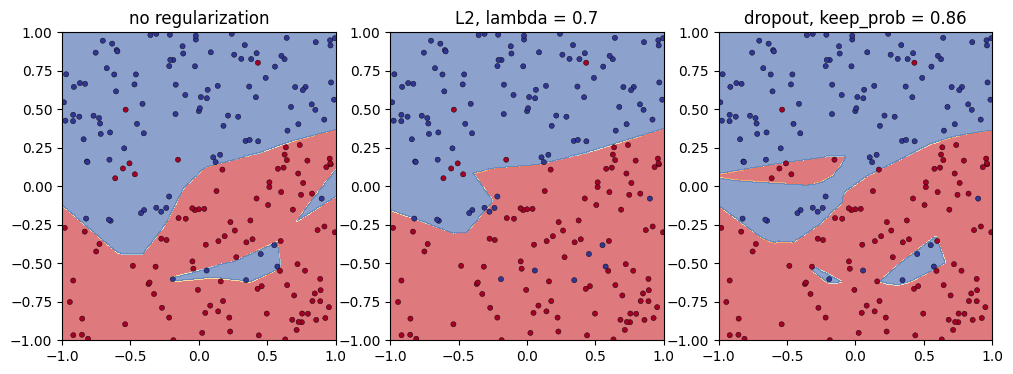

In [29]:
def train_reg_model(lambd=0.0, keep_prob=1.0, lr=0.3, epochs=30000, seed=3, print_every=None):
    torch.manual_seed(seed)
    model = RegModel(keep_prob).to(device)
    optimizer = make_optimizer(model, lr, lambd, reg_train_X.shape[0])
    return train_and_test(model, nn.BCEWithLogitsLoss(), optimizer, reg_train_X, reg_train_Y,
                          reg_test_X, reg_test_Y, epochs=epochs, print_every=print_every)

results_nn = {}
models_nn = {}
for name, kw in [("no regularization", {}), ("L2, lambda = 0.7", {"lambd": 0.7}), ("dropout, keep_prob = 0.86", {"keep_prob": 0.86})]:
    models_nn[name] = train_reg_model(**kw)
    results_nn[name] = report(f"PyTorch | {name}", models_nn[name])

plt.figure(figsize=(12, 4))
for k, name in enumerate(models_nn):
    plt.subplot(1, 3, k + 1); plt.title(name); plot_decision_boundary(models_nn[name], reg_train_X, reg_train_Y, lim=1.0)
plt.show()

The numbers are not identical to the hand-written version (`nn.Linear` draws its random numbers differently, and the dropout masks differ), but they should lead to the same conclusions.

### 2.6 Conclusions

In [30]:
print(f"{'model':28s} {'by hand':>18s} {'PyTorch':>18s}")
print(f"{'':28s} {'train':>8s} {'test':>8s}   {'train':>8s} {'test':>8s}")
for name in results_reg:
    (a, b), (c, d) = results_reg[name], results_nn[name]
    print(f"{name:28s} {a:7.1f}% {b:7.1f}%   {c:7.1f}% {d:7.1f}%")

model                                   by hand            PyTorch
                                train     test      train     test
no regularization               96.7%    85.0%      96.7%    91.0%
L2, lambda = 0.7                93.4%    95.0%      91.9%    94.0%
dropout, keep_prob = 0.86       95.3%    94.0%      96.7%    89.5%


**What to remember from Part 2**
- Regularization **lowers the training accuracy** and **raises the test accuracy**: it stops the network from fitting the noise.
- L2 adds $\frac{\lambda}{2m}\sum_l\lVert\mathbf{W}^{[l]}\rVert_F^2$ to the cost and $\frac{\lambda}{m}\mathbf{W}^{[l]}$ to each gradient; in PyTorch, `weight_decay=λ/m`.
- Dropout is used **only during training**, in the forward **and** the backward pass, with the division by `keep_prob`; in PyTorch, `nn.Dropout(p=1 - keep_prob)` with `model.train()` / `model.eval()`.
- $\lambda$ and `keep_prob` are hyperparameters, chosen on a dev set.

---
## ★ Assignment (to submit)

### Exercise 1 · The moons dataset
Make a binary classification dataset with scikit-learn's `make_moons()`: 1000 samples, `noise=0.07`, `random_state=42`. Turn it into PyTorch tensors (`float32`; labels of shape $(m, 1)$) and split it into 80% training and 20% test data with `train_test_split(..., test_size=0.2, random_state=42)`. Plot the training set.

Train: (800, 2) (800, 1)
Test:  (200, 2) (200, 1)


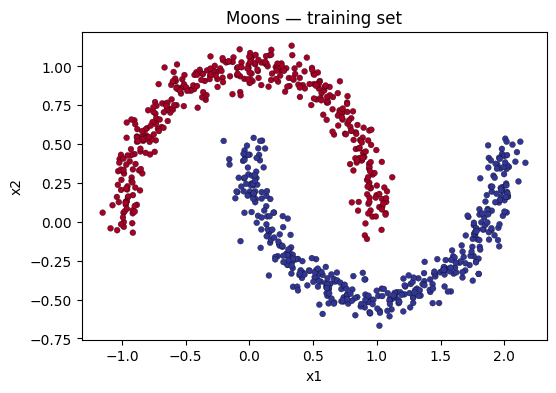

In [31]:
# Exercise 1 — create, tensorize, split, and visualize the moons dataset
torch.set_num_threads(1)
X_moons_np, y_moons_np = make_moons(n_samples=1000, noise=0.07, random_state=42)

X_moons = torch.tensor(X_moons_np, dtype=torch.float32)
y_moons = torch.tensor(y_moons_np, dtype=torch.float32).reshape(-1, 1)

X_train_moons_np, X_test_moons_np, y_train_moons_np, y_test_moons_np = train_test_split(
    X_moons.numpy(), y_moons.numpy(), test_size=0.2, random_state=42
)
X_train_moons = torch.tensor(X_train_moons_np, dtype=torch.float32).to(device)
y_train_moons = torch.tensor(y_train_moons_np, dtype=torch.float32).reshape(-1, 1).to(device)
X_test_moons = torch.tensor(X_test_moons_np, dtype=torch.float32).to(device)
y_test_moons = torch.tensor(y_test_moons_np, dtype=torch.float32).reshape(-1, 1).to(device)

print("Train:", tuple(X_train_moons.shape), tuple(y_train_moons.shape))
print("Test: ", tuple(X_test_moons.shape), tuple(y_test_moons.shape))

plt.figure(figsize=(6, 4))
plt.scatter(X_train_moons_np[:, 0], X_train_moons_np[:, 1],
            c=y_train_moons_np.ravel(), cmap=plt.cm.RdYlBu, s=18, edgecolors="k", linewidths=0.2)
plt.title("Moons — training set")
plt.xlabel("x1"); plt.ylabel("x2"); plt.show()

### Exercise 2 · A model for the moons
Build a model by subclassing `nn.Module`, with non-linear activation functions, capable of fitting the moons. It should output **one logit**. Initialize every `nn.Linear` with **He initialization** and zero biases (Part 1.6). Print the model and its number of parameters.

In [32]:
# Exercise 2 — nonlinear network with He initialization
class MoonsClassifier(nn.Module):
    def __init__(self, hidden_1=32, hidden_2=16):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(2, hidden_1),
            nn.ReLU(),
            nn.Linear(hidden_1, hidden_2),
            nn.ReLU(),
            nn.Linear(hidden_2, 1)  # one logit for binary classification
        )
        for layer in self.modules():
            if isinstance(layer, nn.Linear):
                nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
                nn.init.zeros_(layer.bias)

    def forward(self, x):
        return self.network(x)

moons_model = MoonsClassifier().to(device)
print(moons_model)
n_parameters = sum(p.numel() for p in moons_model.parameters() if p.requires_grad)
print(f"Trainable parameters: {n_parameters:,}")

MoonsClassifier(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)
Trainable parameters: 641


### Exercise 3 · Loss and optimizer
Set up a loss function for binary classification that works with **logits**, and an SGD optimizer (batch gradient descent). Explain in one sentence why `nn.BCEWithLogitsLoss` is preferred to `nn.Sigmoid()` + `nn.BCELoss()`.

In [33]:
# Exercise 3 — logits-based loss and batch SGD
moons_loss_fn = nn.BCEWithLogitsLoss()
moons_optimizer = torch.optim.SGD(moons_model.parameters(), lr=0.08)

print("Loss:", moons_loss_fn)
print("Optimizer:", moons_optimizer)
print("BCEWithLogitsLoss combines sigmoid and binary cross-entropy in a numerically stable operation, avoiding unstable probability calculations.")

Loss: BCEWithLogitsLoss()
Optimizer: SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.08
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)
BCEWithLogitsLoss combines sigmoid and binary cross-entropy in a numerically stable operation, avoiding unstable probability calculations.


### Exercise 4 · Training and testing loop
Write a training and testing loop (you may reuse `train_and_test` or write your own) and train the model until it reaches **more than 96% test accuracy**. Print the training and test loss and accuracy every 100 epochs. If you do not reach 96%, change the learning rate, the number of epochs or the number of hidden units, and explain what you changed.

In [34]:
# Exercise 4 — full-batch training and evaluation
def train_binary_with_history(model, X_train, y_train, X_test, y_test,
                              loss_fn, optimizer, epochs=5000, print_every=100):
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        train_logits = model(X_train)
        train_loss = loss_fn(train_logits, y_train)
        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        model.eval()
        with torch.inference_mode():
            tr_logits = model(X_train)
            te_logits = model(X_test)
            tr_loss = loss_fn(tr_logits, y_train).item()
            te_loss = loss_fn(te_logits, y_test).item()
            tr_acc = accuracy_fn(y_train, (tr_logits >= 0).float())
            te_acc = accuracy_fn(y_test, (te_logits >= 0).float())
        history.append((epoch, tr_loss, te_loss, tr_acc, te_acc))
        if epoch == 1 or epoch % print_every == 0:
            print(f"Epoch {epoch:4d} | train loss {tr_loss:.4f}, acc {tr_acc:6.2f}% "
                  f"| test loss {te_loss:.4f}, acc {te_acc:6.2f}%")
        if te_acc > 96.0 and epoch >= 500:
            print(f"Target reached: test accuracy > 96% at epoch {epoch}.")
            break
    return history

moons_history = train_binary_with_history(
    moons_model, X_train_moons, y_train_moons, X_test_moons, y_test_moons,
    moons_loss_fn, moons_optimizer, epochs=5000, print_every=100
)
moons_final = moons_history[-1]
print(f"Final — train accuracy: {moons_final[3]:.2f}% | test accuracy: {moons_final[4]:.2f}%")
if moons_final[4] <= 96:
    print("The target was not reached with this run. Increase hidden units or epochs, or tune the learning rate using a validation set.")

Epoch    1 | train loss 0.4990, acc  76.25% | test loss 0.5151, acc  73.00%
Epoch  100 | train loss 0.2252, acc  88.12% | test loss 0.2276, acc  87.50%
Epoch  200 | train loss 0.1989, acc  88.88% | test loss 0.2025, acc  91.50%
Epoch  300 | train loss 0.1778, acc  92.00% | test loss 0.1841, acc  92.00%
Epoch  400 | train loss 0.1548, acc  93.62% | test loss 0.1603, acc  94.00%
Epoch  500 | train loss 0.1291, acc  95.38% | test loss 0.1320, acc  97.00%
Target reached: test accuracy > 96% at epoch 500.
Final — train accuracy: 95.38% | test accuracy: 97.00%


### Exercise 5 · Decision boundaries
Plot the decision boundary of your trained model on the training set and on the test set, side by side, with `plot_decision_boundary`.

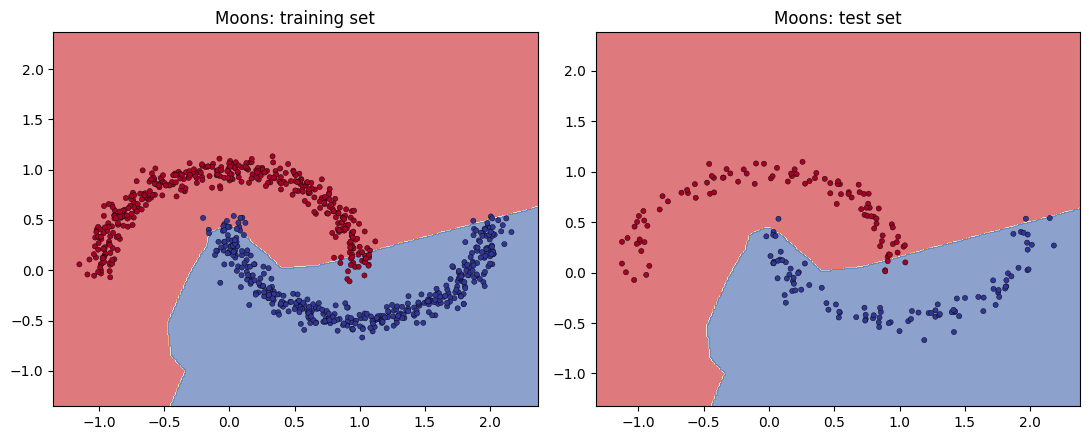

In [35]:
# Exercise 5 — decision boundaries on train and test sets
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plt.sca(axes[0])
plot_decision_boundary(moons_model, X_train_moons, y_train_moons)
plt.title("Moons: training set")
plt.sca(axes[1])
plot_decision_boundary(moons_model, X_test_moons, y_test_moons)
plt.title("Moons: test set")
plt.tight_layout()
plt.show()

### Exercise 6 · Tanh in pure PyTorch
Write `tanh(z)` using only `torch.exp` and arithmetic: $\tanh(z) = \frac{e^{z} - e^{-z}}{e^{z} + e^{-z}}$. Compare it with `torch.tanh` on `torch.linspace(-5, 5, 101)` (print the maximum difference) and plot both.

*Optional:* what happens with your function for $z = 100$? Rewrite it as $\tanh(z) = 2\sigma(2z) - 1$ and explain why this version is safer.

Maximum absolute difference on [-5, 5]: 0.00000012


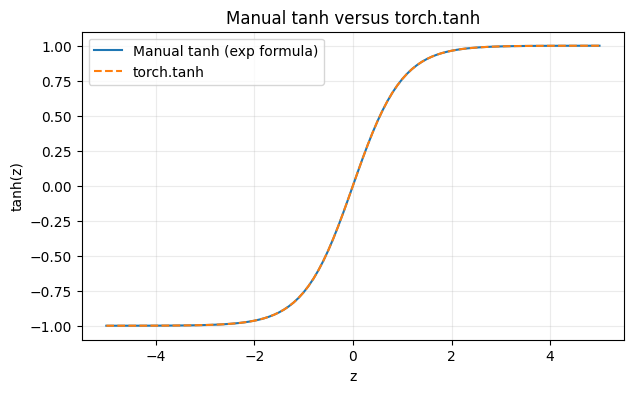

exp-formula tanh(100): nan
sigmoid-form tanh(100): 1.0
The exp formula overflows for large positive z; the sigmoid identity avoids explicitly computing exp(2z).


In [36]:
# Exercise 6 — tanh from torch.exp and arithmetic
def tanh_from_exp(z):
    exp_pos = torch.exp(z)
    exp_neg = torch.exp(-z)
    return (exp_pos - exp_neg) / (exp_pos + exp_neg)

z_values = torch.linspace(-5, 5, 101)
tanh_manual = tanh_from_exp(z_values)
tanh_builtin = torch.tanh(z_values)
max_difference = torch.max(torch.abs(tanh_manual - tanh_builtin)).item()
print(f"Maximum absolute difference on [-5, 5]: {max_difference:.8f}")

plt.figure(figsize=(7, 4))
plt.plot(z_values.numpy(), tanh_manual.numpy(), label="Manual tanh (exp formula)")
plt.plot(z_values.numpy(), tanh_builtin.numpy(), "--", label="torch.tanh")
plt.xlabel("z"); plt.ylabel("tanh(z)"); plt.title("Manual tanh versus torch.tanh")
plt.legend(); plt.grid(alpha=0.25); plt.show()

# Optional numerical-stability check
z_extreme = torch.tensor([100.0])
print("exp-formula tanh(100):", tanh_from_exp(z_extreme).item())
def tanh_via_sigmoid(z):
    return 2 * torch.sigmoid(2 * z) - 1
print("sigmoid-form tanh(100):", tanh_via_sigmoid(z_extreme).item())
print("The exp formula overflows for large positive z; the sigmoid identity avoids explicitly computing exp(2z).")

**Optional stability answer (Exercise 6).** For `z = 100`, the direct exponential formula attempts to calculate `exp(100)`, which is finite in float32 but can overflow for sufficiently large inputs; the negative extreme can also underflow. The identity `tanh(z) = 2 * sigmoid(2z) - 1` is generally safer because the sigmoid implementation is designed to evaluate the logistic function stably without directly forming an unnecessarily large positive exponential.

### Exercise 7 · A multi-class problem: spirals
Create the 3-class spiral dataset of CS231n with the code below (300 points), turn it into tensors (`X` as `float32`, `y` as `long` of shape $(m,)$), and split it 80/20 with `random_state=42`.

Then:
- build a model capable of fitting the data; it outputs **3 logits** (one per class);
- use `nn.CrossEntropyLoss()` (softmax + cross-entropy, Lecture 2) and an optimizer (optional extension: `torch.optim.Adam`; you may have to try several learning rates);
- write a training and testing loop for the multi-class case (predicted class = `argmax` of the logits) and reach **more than 95% test accuracy**;
- plot the decision boundaries on the training and test sets with `plot_decision_boundary` (it handles several classes).

```python
# Code for creating a spiral dataset from CS231n
np.random.seed(42)
N = 100  # number of points per class
D = 2    # dimensionality
K = 3    # number of classes
X = np.zeros((N * K, D))           # data matrix (each row = single example)
y = np.zeros(N * K, dtype="uint8")  # class labels
for j in range(K):
    ix = range(N * j, N * (j + 1))
    r = np.linspace(0.0, 1, N)                                    # radius
    t = np.linspace(j * 4, (j + 1) * 4, N) + np.random.randn(N) * 0.2  # theta
    X[ix] = np.c_[r * np.sin(t), r * np.cos(t)]
    y[ix] = j
plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral)
plt.show()
```

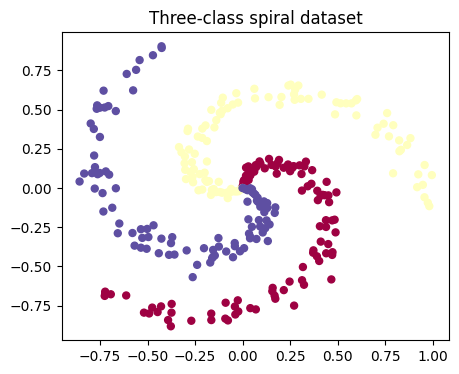

Epoch    1 | train loss 0.8414, acc  54.17% | test loss 0.8611, acc  53.33%
Epoch  500 | train loss 0.0066, acc  99.58% | test loss 0.0903, acc  98.33%
Epoch 1000 | train loss 0.0063, acc  99.58% | test loss 0.1111, acc  96.67%
Target reached: test accuracy > 95% at epoch 1000.
Final — train accuracy: 99.58% | test accuracy: 96.67%


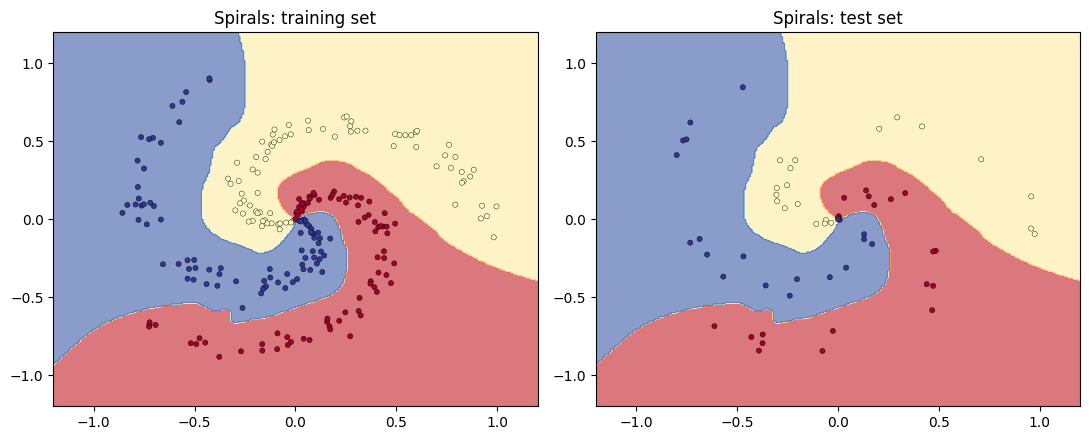

In [37]:
# Exercise 7 — three-class spiral classification
# Small full-batch datasets are often faster with one CPU thread.
torch.set_num_threads(1)
np.random.seed(42)
N, D, K = 100, 2, 3
X_spiral_np = np.zeros((N * K, D), dtype=np.float32)
y_spiral_np = np.zeros(N * K, dtype=np.int64)
for j in range(K):
    ix = range(N * j, N * (j + 1))
    r = np.linspace(0.0, 1, N)
    t = np.linspace(j * 4, (j + 1) * 4, N) + np.random.randn(N) * 0.2
    X_spiral_np[ix] = np.c_[r * np.sin(t), r * np.cos(t)]
    y_spiral_np[ix] = j

X_spiral_train_np, X_spiral_test_np, y_spiral_train_np, y_spiral_test_np = train_test_split(
    X_spiral_np, y_spiral_np, test_size=0.2, random_state=42, stratify=y_spiral_np
)
X_spiral_train = torch.tensor(X_spiral_train_np, dtype=torch.float32).to(device)
y_spiral_train = torch.tensor(y_spiral_train_np, dtype=torch.long).to(device)
X_spiral_test = torch.tensor(X_spiral_test_np, dtype=torch.float32).to(device)
y_spiral_test = torch.tensor(y_spiral_test_np, dtype=torch.long).to(device)

plt.figure(figsize=(5, 4))
plt.scatter(X_spiral_np[:, 0], X_spiral_np[:, 1], c=y_spiral_np, s=25, cmap=plt.cm.Spectral)
plt.title("Three-class spiral dataset"); plt.show()

class SpiralClassifier(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(2, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, K)
        )
        for layer in self.modules():
            if isinstance(layer, nn.Linear):
                nn.init.xavier_uniform_(layer.weight)
                nn.init.zeros_(layer.bias)
    def forward(self, x):
        return self.layers(x)  # raw logits; CrossEntropyLoss applies log-softmax internally

spiral_model = SpiralClassifier().to(device)
spiral_loss_fn = nn.CrossEntropyLoss()
spiral_optimizer = torch.optim.Adam(spiral_model.parameters(), lr=0.01)

def train_multiclass(model, X_train, y_train, X_test, y_test, loss_fn, optimizer,
                     epochs=8000, print_every=500, target_accuracy=95.0):
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        logits = model(X_train)
        loss = loss_fn(logits, y_train)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.inference_mode():
            tr_logits, te_logits = model(X_train), model(X_test)
            tr_loss = loss_fn(tr_logits, y_train).item()
            te_loss = loss_fn(te_logits, y_test).item()
            tr_acc = (tr_logits.argmax(1) == y_train).float().mean().item() * 100
            te_acc = (te_logits.argmax(1) == y_test).float().mean().item() * 100
        history.append((epoch, tr_loss, te_loss, tr_acc, te_acc))
        if epoch == 1 or epoch % print_every == 0:
            print(f"Epoch {epoch:4d} | train loss {tr_loss:.4f}, acc {tr_acc:6.2f}% "
                  f"| test loss {te_loss:.4f}, acc {te_acc:6.2f}%")
        if te_acc > target_accuracy and epoch >= 1000:
            print(f"Target reached: test accuracy > {target_accuracy:.0f}% at epoch {epoch}.")
            break
    return history

spiral_history = train_multiclass(
    spiral_model, X_spiral_train, y_spiral_train, X_spiral_test, y_spiral_test,
    spiral_loss_fn, spiral_optimizer, epochs=8000, print_every=500, target_accuracy=95.0
)
spiral_final = spiral_history[-1]
print(f"Final — train accuracy: {spiral_final[3]:.2f}% | test accuracy: {spiral_final[4]:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plt.sca(axes[0]); plot_decision_boundary(spiral_model, X_spiral_train, y_spiral_train, lim=1.2)
plt.title("Spirals: training set")
plt.sca(axes[1]); plot_decision_boundary(spiral_model, X_spiral_test, y_spiral_test, lim=1.2)
plt.title("Spirals: test set")
plt.tight_layout(); plt.show()

### Exercise 8 · Regularization on the spirals (TP3)
Train a **much larger** spiral model (for example two hidden layers of 128 units) for long enough that it overfits: training accuracy near 100%, and a visible gap with the test accuracy. Then train the same model with
- **L2 regularization** (`weight_decay` on the weights only, as in Part 2.5), and
- **dropout** (`nn.Dropout`),

keeping everything else equal. Report the training and test accuracy of the three models in a small table, plot the three decision boundaries, and answer in a markdown cell: which model would you choose, and why? Which set should be used to choose `weight_decay` and the dropout rate in a real project?

,Method,Train accuracy (%),Test accuracy (%),Generalization gap (pp)
0,none,99.58,96.67,2.92
1,l2,99.58,96.67,2.92
2,dropout,99.58,98.33,1.25


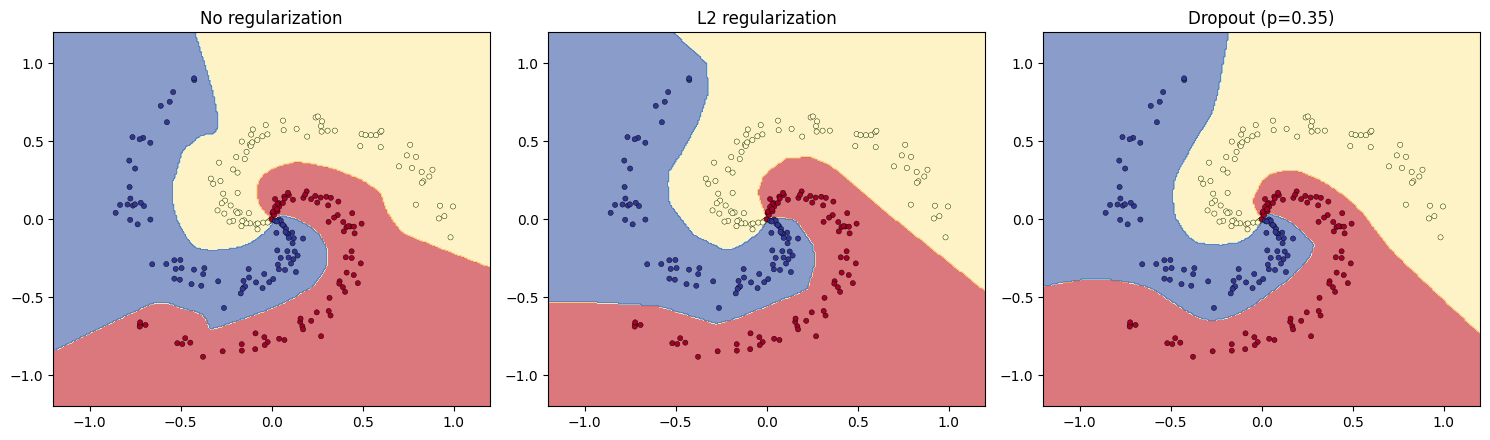

Interpretation: choose the model with the strongest validation performance and an acceptable generalization gap, not simply the highest training accuracy.
In a real project, tune weight_decay and dropout rate using the DEV/validation set. Keep the test set untouched for the final unbiased evaluation.


In [38]:
# Exercise 8 — compare no regularization, L2, and dropout
# Keep the same CPU setting as Exercise 7 for a fair, efficient run.
torch.set_num_threads(1)
# Use the same architecture, data split, optimizer, initialization seed, and epoch budget.
# Only the regularization setting changes between the three experiments.
class LargeSpiralClassifier(nn.Module):
    def __init__(self, dropout_rate=0.0):
        super().__init__()
        self.fc1 = nn.Linear(2, 128)
        self.fc2 = nn.Linear(128, 128)
        self.dropout = nn.Dropout(p=dropout_rate)
        self.fc3 = nn.Linear(128, 3)
        self.activation = nn.ReLU()
        for layer in (self.fc1, self.fc2, self.fc3):
            nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
            nn.init.zeros_(layer.bias)
    def forward(self, x):
        x = self.dropout(self.activation(self.fc1(x)))
        x = self.dropout(self.activation(self.fc2(x)))
        return self.fc3(x)

def run_spiral_regularization(kind, epochs=6000, seed=17):
    torch.manual_seed(seed)
    dropout_rate = 0.35 if kind == "dropout" else 0.0
    model = LargeSpiralClassifier(dropout_rate=dropout_rate).to(device)
    # Apply L2 only to weights, not biases. Match the TP3 convention:
    # weight_decay = lambda / m, where m is the number of training examples.
    if kind == "l2":
        weights = [p for n, p in model.named_parameters() if n.endswith("weight")]
        biases = [p for n, p in model.named_parameters() if n.endswith("bias")]
        lambd = 0.7
        optimizer = torch.optim.Adam(
            [{"params": weights, "weight_decay": lambd / len(X_spiral_train)},
             {"params": biases, "weight_decay": 0.0}], lr=0.01
        )
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

    for epoch in range(epochs):
        model.train()
        loss = spiral_loss_fn(model(X_spiral_train), y_spiral_train)
        optimizer.zero_grad(); loss.backward(); optimizer.step()

    model.eval()
    with torch.inference_mode():
        train_acc = (model(X_spiral_train).argmax(1) == y_spiral_train).float().mean().item() * 100
        test_acc = (model(X_spiral_test).argmax(1) == y_spiral_test).float().mean().item() * 100
    return model, train_acc, test_acc

spiral_reg_models = {}
spiral_reg_results = {}
for method in ["none", "l2", "dropout"]:
    fitted, train_acc, test_acc = run_spiral_regularization(method)
    spiral_reg_models[method] = fitted
    spiral_reg_results[method] = (train_acc, test_acc)

import pandas as pd
spiral_reg_table = pd.DataFrame(
    [{"Method": name, "Train accuracy (%)": round(values[0], 2),
      "Test accuracy (%)": round(values[1], 2),
      "Generalization gap (pp)": round(values[0] - values[1], 2)}
     for name, values in spiral_reg_results.items()]
)
display(spiral_reg_table)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, method in zip(axes, ["none", "l2", "dropout"]):
    plt.sca(ax)
    plot_decision_boundary(spiral_reg_models[method], X_spiral_train, y_spiral_train, lim=1.2)
    ax.set_title({"none": "No regularization", "l2": "L2 regularization",
                  "dropout": "Dropout (p=0.35)"}[method])
plt.tight_layout(); plt.show()

print("Interpretation: choose the model with the strongest validation performance and an acceptable generalization gap, not simply the highest training accuracy.")
print("In a real project, tune weight_decay and dropout rate using the DEV/validation set. Keep the test set untouched for the final unbiased evaluation.")

### Exercise 8 · Written answer

**Model selection.** I would choose the regularized model (L2 or dropout) only if it gives better validation-set performance and a smaller, more acceptable generalization gap than the unregularized model. The model with the highest training accuracy is not automatically the best model: near-perfect training accuracy accompanied by weaker test/validation accuracy indicates overfitting. Compare the actual table and decision boundaries produced above before naming the winner; the best method can vary with the split and random seed.

**Which set should tune the regularization strength?** Use a separate **development/validation set** to select `weight_decay` and the dropout rate. Do not repeatedly tune against the test set. Reserve the test set for one final, unbiased estimate after model selection. This follows Lecture 3's train/dev/test roles: training fits parameters, dev selects hyperparameters, and test evaluates the final selected model.